In [15]:
import pandas as pd
import numpy as np

data = {
    'name': ['김철수', '이영희', '박민수', '최지훈', '정소희'],
    'age': [25, 30, np.nan, 22, 35],
    'city': ['서울', None, '인천', '서울', '대전'],
    'score': [90, 85, np.nan, 80, 92]
}

df = pd.DataFrame(data)

# 결측치 여부 확인
df.isnull()
df.isna()

# column별, row별 결측치 개수 확인
df.isnull().sum()
df.isnull().sum(axis=1)

# 특정 column, row 결측치 확인
df[df.isnull().any(axis=1)]
df[df['age'].isnull()]

# 결측치가 아닌 항목 확인
df.notnull()

# 결측치 비율
print(df.shape[0])
print(df.shape[1])
df.isnull().sum().sum() / (df.shape[0] * df.shape[1]) * 100

5
4


np.float64(15.0)

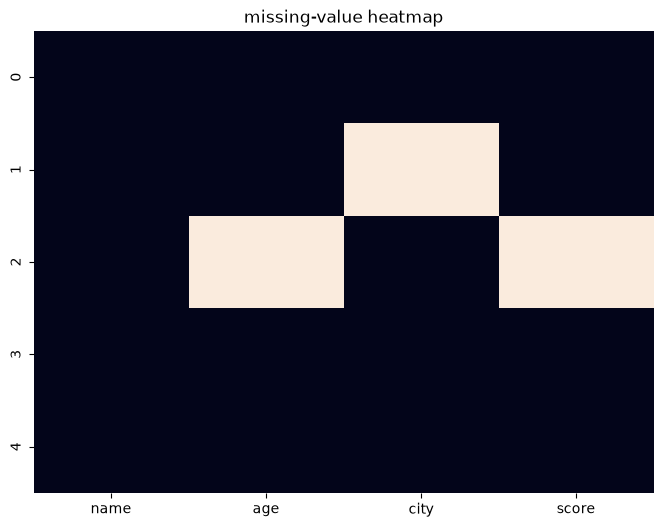

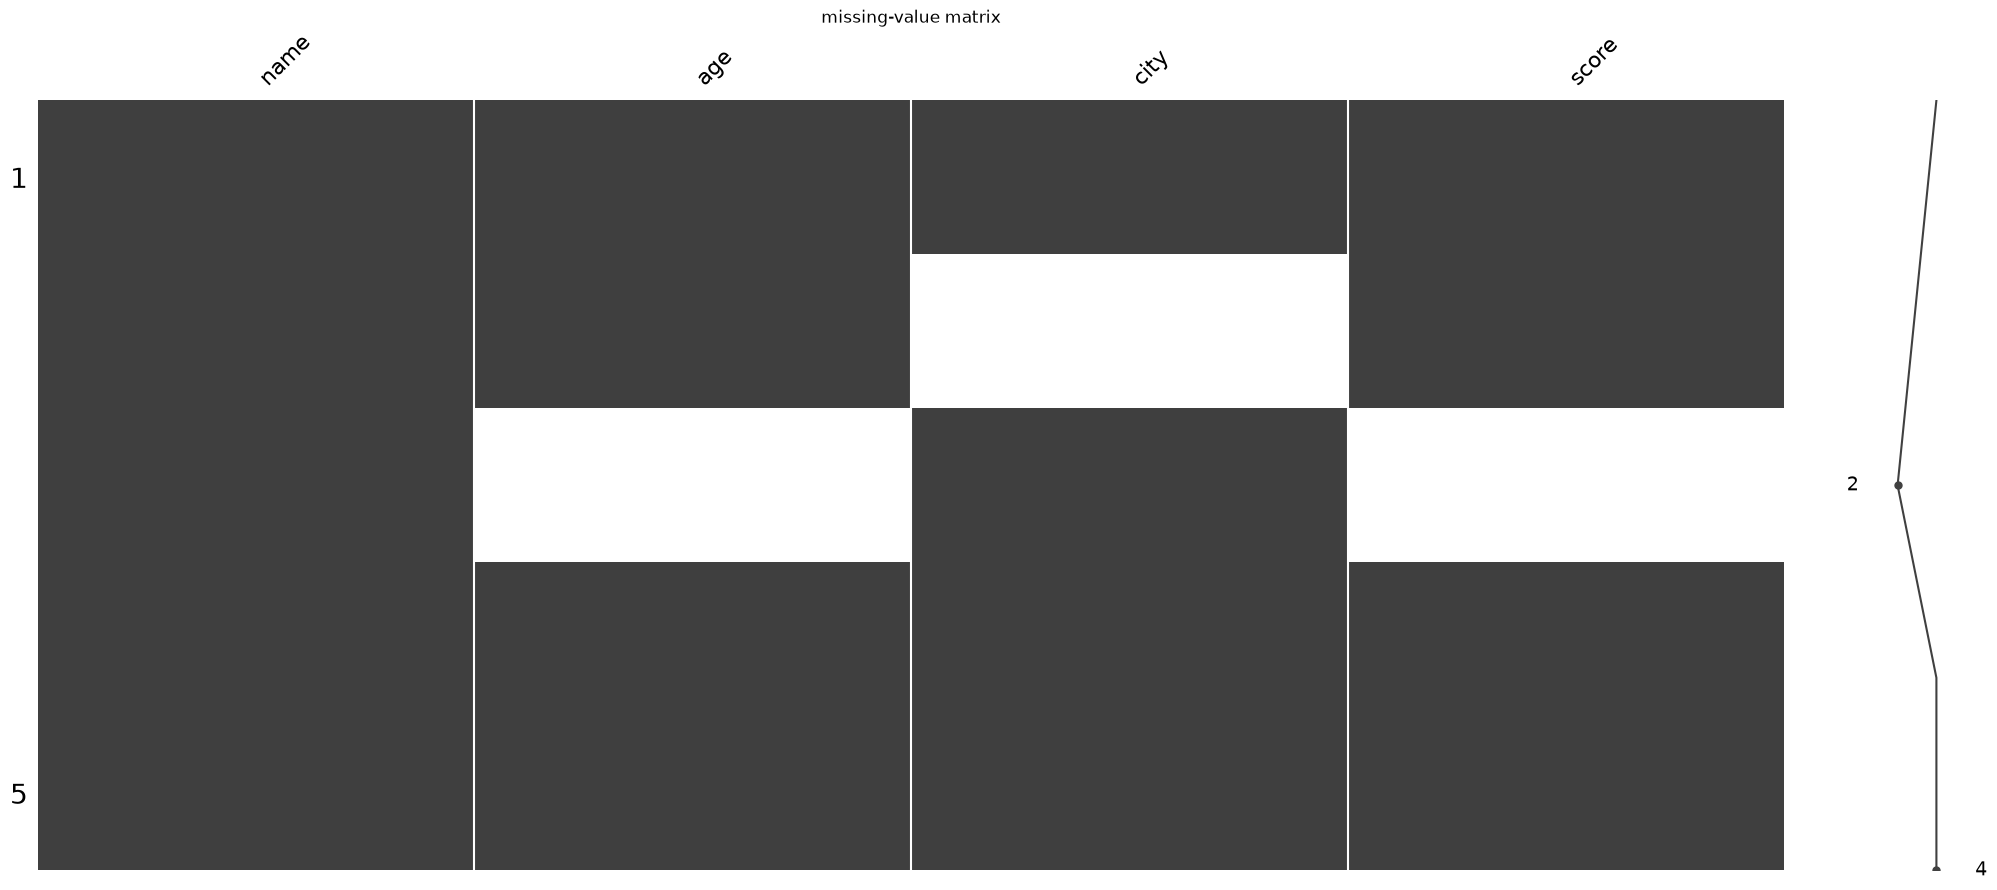

In [20]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

data = {
    'name': ['김철수', '이영희', '박민수', '최지훈', '정소희'],
    'age': [25, 30, np.nan, 22, 35],
    'city': ['서울', None, '인천', '서울', '대전'],
    'score': [90, 85, np.nan, 80, 92]
}

df = pd.DataFrame(data)

# 결측치 heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.isnull(), cbar=False)
plt.title('missing-value heatmap')
plt.show()

# 결측치 matrix
msno.matrix(df)
plt.title('missing-value matrix')
plt.show()

In [22]:
import pandas as pd
import numpy as np

scores = [72, 68, 75, 282, 64, 31, 78, 69, 88, 92, 22, 84, 61]
student_numbers = list(range(1001, 1001 + len(scores)))

df = pd.DataFrame({
    'student_number': student_numbers,
    'score': scores
})

# 사분위 범위 경계값 계산
q1 = df['score'].quantile(0.25)
q3 = df['score'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# IQR 통계량 출력
print(q1)
print(q3)
print(iqr)
print(lower_bound)
print(upper_bound)

64.0
84.0
20.0
34.0
114.0


In [28]:
import pandas as pd
import numpy as np

scores = [72, 68, 75, 282, 64, 31, 78, 69, 88, 92, -90, 22, 84, 61]
student_numbers = list(range(1001, 1001 + len(scores)))

df = pd.DataFrame({
    'student_number': student_numbers,
    'score': scores
})

# Z-Score 계산
score_avg = df['score'].mean()
score_stddev = df['score'].std()
df['score_z'] = (df['score'] - score_avg) / score_stddev
df

# 임계값 설정 및 이상치 여부 판단
threshold = 2
df['outlier_yn'] = df['score_z'].abs() > threshold

# 이상치 데이터 출력
df[df['outlier_yn']]

# 이상치 비율 출력
df['outlier_yn'].mean() * 100

np.float64(14.285714285714285)

In [36]:
import pandas as pd
import numpy as np

file_path = 'raw_large_shopping_customer.csv'
df = pd.read_csv(file_path)
print(df.isnull().sum())

df_cleaned = df.dropna(thresh=df.shape[1] - 1)

# 나이, 소득 평균값 대치 및 결과 출력
df_cleaned.loc[:, ['나이', '소득']] = df_cleaned[['나이', '소득']].fillna(df_cleaned[['나이', '소득']].mean())

# 지출, 평균구매횟수 선형보간법 적용
df_cleaned.loc[:, ['지출', '평균구매횟수']] = df_cleaned[['지출', '평균구매횟수']].interpolate(method='linear')

df_cleaned.to_csv('cleaned_large_shopping_customer.csv', index=False, encoding='utf-8-sig')

ID         0
나이        50
소득        50
지출        50
평균구매횟수    50
dtype: int64
